# Oscillations and waves 3: The wave equation

*Learning path: oscillations and waves, part 3 of 7.* [Index](README.md) · Previous: [Coupled oscillators](02-coupled-oscillators.ipynb) · Next: [Sound and the Fourier transform](04-sound-and-fourier.ipynb)

Pluck a guitar string in the middle, then pluck it close to the bridge. The note is the same, but the second sounds
brighter and more metallic. Why? The string can vibrate in many patterns at once, each at a whole multiple of the
lowest frequency, and where you pluck decides how much of each you get. This lesson derives the equation for a
vibrating string, solves it in two ways (travelling pulses and standing waves), and uses Fourier series to take a
pluck apart into its harmonics.

**Who this is for.** You have done [lesson 2](02-coupled-oscillators.ipynb) and know partial derivatives.

**What you will be able to do afterwards:**

1. derive the wave equation for a string and compute its wave speed;
2. show that any shape $f(x - ct)$ travels without change;
3. find the standing waves of a string fixed at both ends, and its harmonics;
4. expand a plucked string in a Fourier series and explain the tone of a pluck.

Plan about an hour and a half.

## 1. From a chain to a string

In lesson 2 the chain of masses obeyed $m\ddot x_j = k(x_{j+1} - 2x_j + x_{j-1})$. For a string under tension $T$ with
mass $\mu$ per metre, the masses become $\mu\,\Delta x$ and the bracket becomes a second difference, which as
$\Delta x \to 0$ is $\Delta x^2\,\partial^2 u/\partial x^2$. Sideways displacements $u(x, t)$ then obey the
**wave equation**

$$\frac{\partial^2u}{\partial t^2} = c^2\frac{\partial^2u}{\partial x^2}, \qquad c = \sqrt{T/\mu}.$$

A guitar's thinnest string: tension 70 N, 0.4 g per metre, 65 cm between the nut and the bridge. Its wave speed, and
(section 3) its lowest note $c/2L$:

In [1]:
Tn = 70 N;
mu = 0.4 g/m;
c = sqrt(Tn/mu);
eval(convert(c, m/s), 4)
eval(convert(c/(2*0.65 m), Hz), 4)

418.3 m/s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

321.8 Hz

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

322 Hz, close to the E at 330 Hz the string is tuned to. Tighten it a little more and it is in tune.

**Try this.** The thickest string on the same guitar plays E two octaves lower (82 Hz) with about the same tension.
How heavy is it per metre?

## 2. Travelling waves

Any function of $x - vt$ solves the wave equation with speed $v$. A bump:

In [2]:
u = exp(-(x - v*t)^2);
simplify(diff(diff(u, t), t) - v^2*diff(diff(u, x), x))

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

It is zero, for any shape, by the chain rule: both second derivatives are $f''$, the time one with a factor $v^2$.
So a shape $f(x - vt)$ moves to the right at speed $v$ without changing; $g(x + vt)$ moves left. In 1747 d'Alembert
showed that every solution is such a sum. Here is a pulse travelling at $v = 1$ (press play):

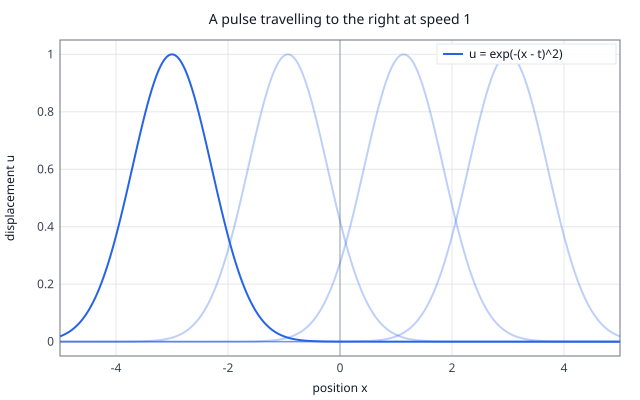

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
p = animate(exp(-(x - t)^2), x, -5, 5, t, -3, 3, 30);
p = legend(p, "u = exp(-(x - t)^2)");
labels(title(p, "A pulse travelling to the right at speed 1"), "position x", "displacement u")

**Try this.** Animate `exp(-(x - t)^2) + exp(-(x + t)^2)`. What happens when the pulses meet?

## 3. Standing waves and harmonics

A guitar string is fixed at both ends: $u(0, t) = u(L, t) = 0$. Look for solutions that keep their shape and only
change size, $u = X(x)\cos\omega t$. Then $X'' = -(\omega/c)^2X$, so $X$ is a sine, and $X(L) = 0$ allows only
$\sin(n\pi x/L)$ with $n = 1, 2, 3, \ldots$ The frequencies are

$$f_n = \frac{nc}{2L} = n f_1.$$

These are the **harmonics**: the fundamental, the octave above, then the fifth above that, and so on. They are the
continuous version of the chain's normal modes. With $L = c = 1$, the third harmonic:

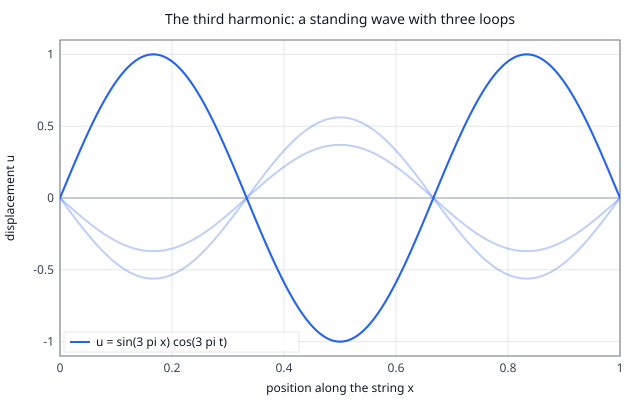

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
p = animate(sin(3*pi*x)*cos(3*pi*t), x, 0, 1, t, 0, 2/3, 30);
p = legend(p, "u = sin(3 pi x) cos(3 pi t)");
labels(title(p, "The third harmonic: a standing wave with three loops"), "position along the string x", "displacement u")

The points $x = 1/3$ and $2/3$ (**nodes**) never move. A guitarist who touches the string lightly at a third of its
length kills every harmonic without a node there, leaving the third harmonic and its multiples: a "harmonic" an octave
and a fifth above the open string.

**Try this.** Where must the string be touched to sound the second harmonic?

## 4. The plucked string

Pull the string aside at a point $a$ (with $L = 1$) to height 1 and let go. The starting shape is a triangle, and the
solution is a sum of standing waves, $u = \sum_n b_n\sin(n\pi x)\cos(n\pi t)$, with the $b_n$ chosen so that at $t =
0$ the sum is the triangle. Multiplying by $\sin(n\pi x)$ and integrating picks out one coefficient
(the sines are orthogonal), the **Fourier sine series**:

In [5]:
assume(n, integer);
b(n, a) := 2*(integrate(x/a*sin(n*pi*x), x, 0, a) + integrate((1 - x)/(1 - a)*sin(n*pi*x), x, a, 1));
simplify(b(n, a))

2*sin(pi*a*n)/(pi^2*a*n^2*(1-a))

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

$b_n = \dfrac{2\sin(n\pi a)}{\pi^2 a(1-a)n^2}$. Pluck in the middle, $a = \tfrac12$:

In [6]:
simplify(b(n, 1/2))

8*sin(pi*n/2)/(pi^2*n^2)

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

Every even harmonic is missing ($\sin(n\pi/2) = 0$), because they all have a node in the middle, where the pluck is
largest. Compare the harmonic content of a pluck in the middle and one at a fifth of the length, near the bridge:

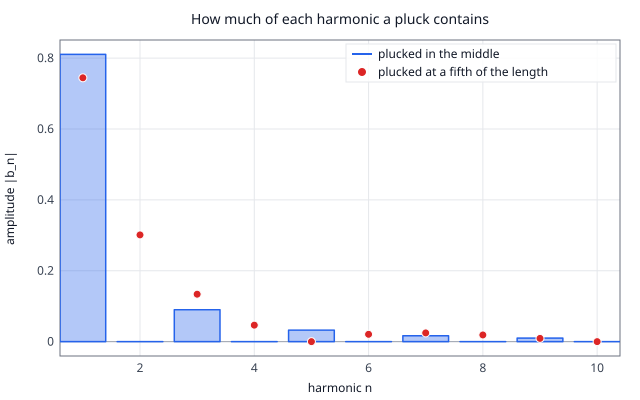

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
A = []; B = [];
for k in 1:10
  A = append(A, abs(eval(b(k, 1/2))));
  B = append(B, abs(eval(b(k, 1/5))));
end
p = bar(1:10, A);
p = show(p, scatter(1:10, B));
p = legend(p, "plucked in the middle", "plucked at a fifth of the length");
labels(title(p, "How much of each harmonic a pluck contains"), "harmonic n", "amplitude |b_n|")

Plucked near the bridge, the string has more of the higher harmonics (and lacks the 5th and 10th, which have a node
there): the brighter tone. Add up the first 25 terms for the middle pluck and let it move:

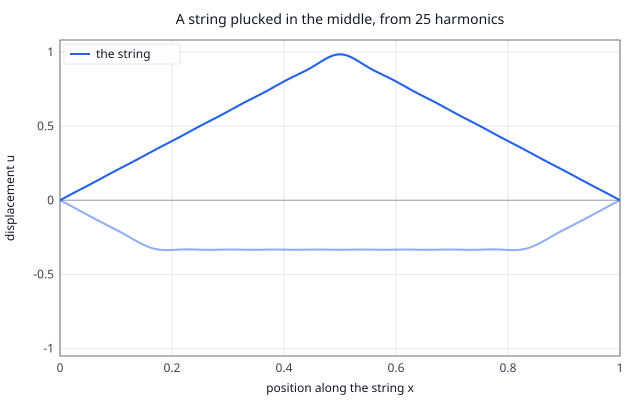

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
U = 0;
for k in 1:25
  U = U + b(k, 1/2)*sin(k*pi*x)*cos(k*pi*t);
end
p = animate(U, x, 0, 1, t, 0, 2, 40);
p = legend(p, "the string");
labels(title(p, "A string plucked in the middle, from 25 harmonics"), "position along the string x", "displacement u")

The triangle does not swing as a whole. Its corner splits into two corners that run outwards at speed 1 (d'Alembert's
travelling waves again), reflect upside down at the ends, and meet in the middle at $t = 1$, where the shape is the
original triangle turned over. After $t = 2$ it starts again: the period of the fundamental.

**Try this.** At $t = \tfrac12$ the string is a trapezoid. Check by plotting `subs(U, t, 1/2)`.

## Summary

* A string under tension $T$ with mass $\mu$ per metre obeys $u_{tt} = c^2u_{xx}$ with $c = \sqrt{T/\mu}$.
* Every solution is $f(x - ct) + g(x + ct)$: shapes travel without change.
* Fixed ends allow standing waves $\sin(n\pi x/L)$ at the harmonics $f_n = nc/2L$.
* A pluck is a Fourier series of harmonics, with $b_n \propto \sin(n\pi a)/n^2$; where you pluck sets the tone.

Next: [sound and the Fourier transform](04-sound-and-fourier.ipynb), where the harmonics become a spectrum.

## Exercises

1. **Tuning.** By what percentage must the tension of the string in section 1 rise to bring it from 322 Hz to 330 Hz?
2. **Wave speed on a rope.** A 10 m rope of mass 2 kg is pulled with 100 N. How long does a pulse take to cross it?
3. **Struck string.** A piano hammer gives the string a starting velocity instead of a starting shape. Show that then
   $u = \sum_n c_n\sin(n\pi x)\sin(n\pi t)$, and explain why the $c_n$ fall off more slowly (like $1/n$ for a narrow
   hammer).
4. **Square wave.** Find the Fourier sine series of the function equal to 1 on $(0, 1)$, and plot the sum of the
   first 1, 3 and 10 nonzero terms. What happens near the ends (the Gibbs phenomenon)?
5. **Energy.** The energy in harmonic $n$ is proportional to $n^2b_n^2$. For the middle pluck, what fraction is in
   the fundamental? (Use $\sum_{\text{odd } n}1/n^2 = \pi^2/8$.)
6. **Pipe.** In a flute (open at both ends) the air pressure has nodes at both ends; in a clarinet (closed at one
   end), a node at one end and a maximum at the other. Which harmonics does each play?

## Hints and answers

* **Section 1, Try this.** Frequency goes like $1/\sqrt\mu$, so $4^2 = 16$ times heavier: about 6.4 g per metre.
* **Section 2, Try this.** They pass through each other unchanged; at the moment they overlap, the displacement is the
  sum, twice as high.
* **Section 3, Try this.** In the middle.
* **Section 4, Try this.** `p = plot(subs(U, t, 1/2), x, 0, 1)`: flat in the middle at height $\tfrac12$.
* **Exercise 1.** $(330/322)^2 \approx 1.050$: 5% more tension.
* **Exercise 2.** $c = \sqrt{100/0.2} \approx 22.4$ m/s, so 0.45 s.
* **Exercise 3.** The velocity is $\sum c_n n\pi\sin(n\pi x)$ at $t = 0$; for a narrow hammer that velocity is a spike,
  whose coefficients don't fall off, so $c_n \propto 1/n$.
* **Exercise 4.** $b_n = 4/(n\pi)$ for odd $n$; the partial sums overshoot near the ends by about 9%, however many
  terms you take.
* **Exercise 5.** $n^2b_n^2 \propto 1/n^2$, so the fundamental has $1/(\pi^2/8) \approx 81\%$.
* **Exercise 6.** Flute: all harmonics. Clarinet: only the odd ones, which gives it its hollow sound.

## Sources

1. J. le R. d'Alembert, "Recherches sur la courbe que forme une corde tendue mise en vibration", *Histoire de
   l'Académie Royale des Sciences et Belles Lettres de Berlin* 3, 214–219 (1747).
2. D. Bernoulli, "Réflexions et éclaircissemens sur les nouvelles vibrations des cordes", same journal, 9, 147–172
   (1753): the string as a sum of harmonics.
3. J. Fourier, *Théorie analytique de la chaleur* (1822).
4. N. H. Fletcher and T. D. Rossing, *The Physics of Musical Instruments*, 2nd ed., Springer (1998), chapters 2 and 9.